# Lab 4 benchmark analysis

Interactive view of the same data behind `BENCHMARKS.md`. The notebook imports
`load` and `plot_metric` from `scripts/plot_bench.py`, so it cannot drift from
the committed plots.

Run Jupyter from `lab04/analysis/` (or `lab04/`). Requirements: `jupyter` and
`matplotlib`; no pandas. The input is
`output/ubuntu/benchmarks/summary_ubuntu_gcc.csv`, produced by
`scripts/run_benchmarks.sh gcc`.


In [1]:
from pathlib import Path
import sys
import tempfile

from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
if not (ROOT / "scripts" / "plot_bench.py").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
from plot_bench import load, plot_metric

DATA = ROOT / "output/ubuntu/benchmarks/summary_ubuntu_gcc.csv"
rows = load(DATA)
print(f"{len(rows)} summary rows from {DATA}")


24 summary rows from /home/han-sui/Downloads/NT219/lab04/output/ubuntu/benchmarks/summary_ubuntu_gcc.csv


In [2]:
order = ["sha256", "sha512", "sha3-256", "sha3-512"]
sizes = sorted({int(r["size_mib"]) for r in rows})
by = {(r["algo"], int(r["size_mib"]), r["io"]): r for r in rows}

lines = [
    "| Algo | Size | stream MB/s | mmap MB/s | mmap vs stream |",
    "|---|---:|---:|---:|---:|",
]
for algo in order:
    for size in sizes:
        st, mm = by[(algo, size, "stream")], by[(algo, size, "mmap")]
        delta = (float(mm["mbps_mean"]) / float(st["mbps_mean"]) - 1) * 100
        lines.append(
            f"| {algo.upper()} | {size} MiB | {float(st['mbps_mean']):.0f} ± {float(st['mbps_ci95']):.0f} "
            f"| {float(mm['mbps_mean']):.0f} ± {float(mm['mbps_ci95']):.0f} | {delta:+.1f}% |"
        )
display(Markdown("\n".join(lines)))


| Algo | Size | stream MB/s | mmap MB/s | mmap vs stream |
|---|---:|---:|---:|---:|
| SHA256 | 1 MiB | 1519 ± 7 | 1510 ± 8 | -0.6% |
| SHA256 | 100 MiB | 1421 ± 5 | 1536 ± 7 | +8.1% |
| SHA256 | 1024 MiB | 1370 ± 19 | 1440 ± 20 | +5.1% |
| SHA512 | 1 MiB | 685 ± 3 | 674 ± 3 | -1.7% |
| SHA512 | 100 MiB | 672 ± 3 | 701 ± 2 | +4.3% |
| SHA512 | 1024 MiB | 639 ± 8 | 663 ± 6 | +3.9% |
| SHA3-256 | 1 MiB | 430 ± 2 | 437 ± 2 | +1.7% |
| SHA3-256 | 100 MiB | 402 ± 4 | 402 ± 3 | -0.2% |
| SHA3-256 | 1024 MiB | 386 ± 3 | 405 ± 4 | +4.9% |
| SHA3-512 | 1 MiB | 234 ± 1 | 238 ± 1 | +1.9% |
| SHA3-512 | 100 MiB | 224 ± 2 | 222 ± 1 | -1.1% |
| SHA3-512 | 1024 MiB | 216 ± 2 | 216 ± 2 | +0.1% |

In [3]:
for size in sizes:
    ranked = sorted(order, key=lambda a: float(by[(a, size, "stream")]["mbps_mean"]), reverse=True)
    print(f"{size:>4} MiB stream: " + " > ".join(
        f"{a} {float(by[(a, size, 'stream')]['mbps_mean']):.0f} MB/s" for a in ranked))


   1 MiB stream: sha256 1519 MB/s > sha512 685 MB/s > sha3-256 430 MB/s > sha3-512 234 MB/s
 100 MiB stream: sha256 1421 MB/s > sha512 672 MB/s > sha3-256 402 MB/s > sha3-512 224 MB/s
1024 MiB stream: sha256 1370 MB/s > sha512 639 MB/s > sha3-256 386 MB/s > sha3-512 216 MB/s


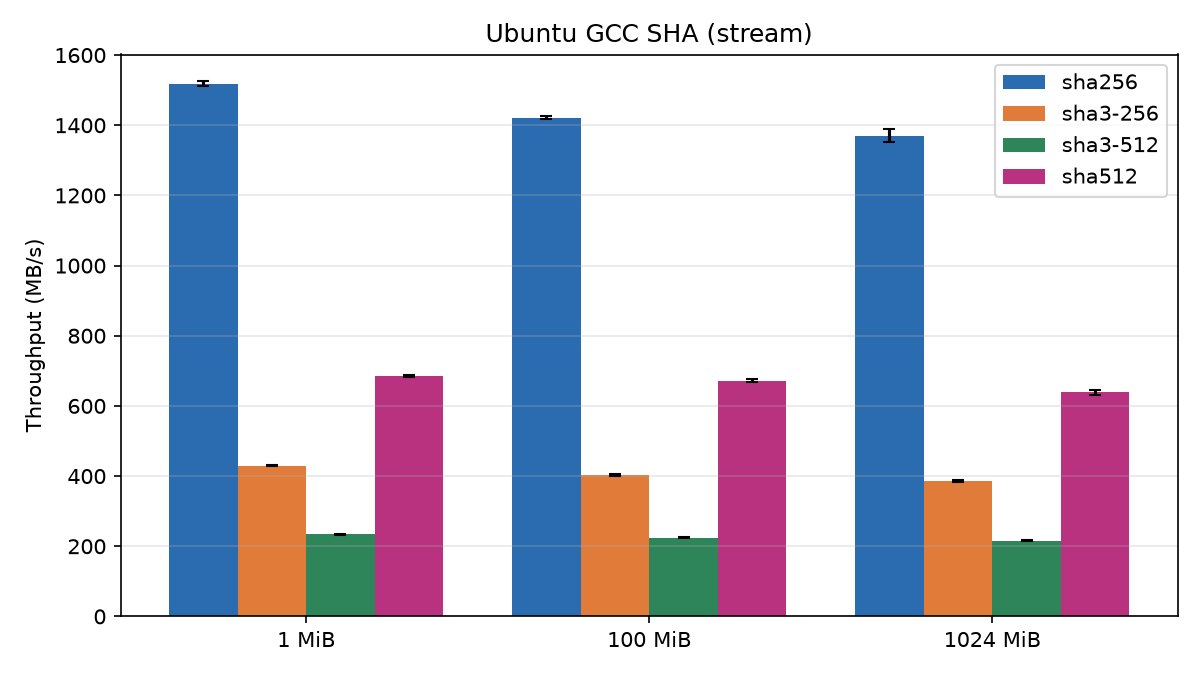

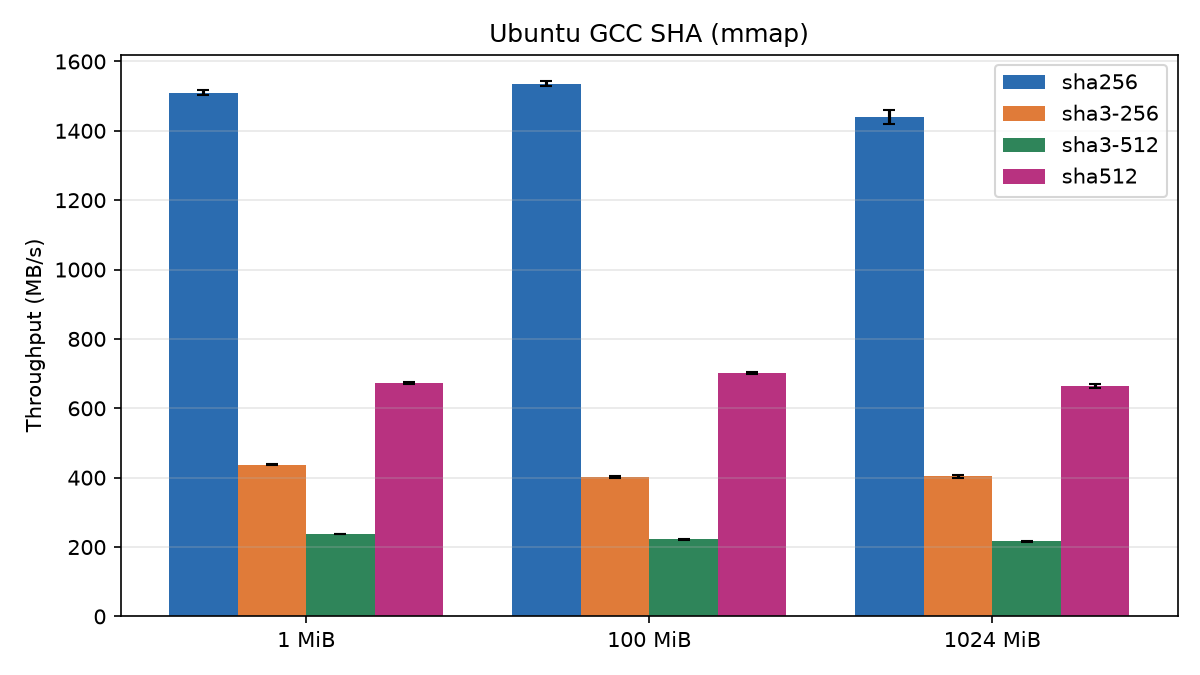

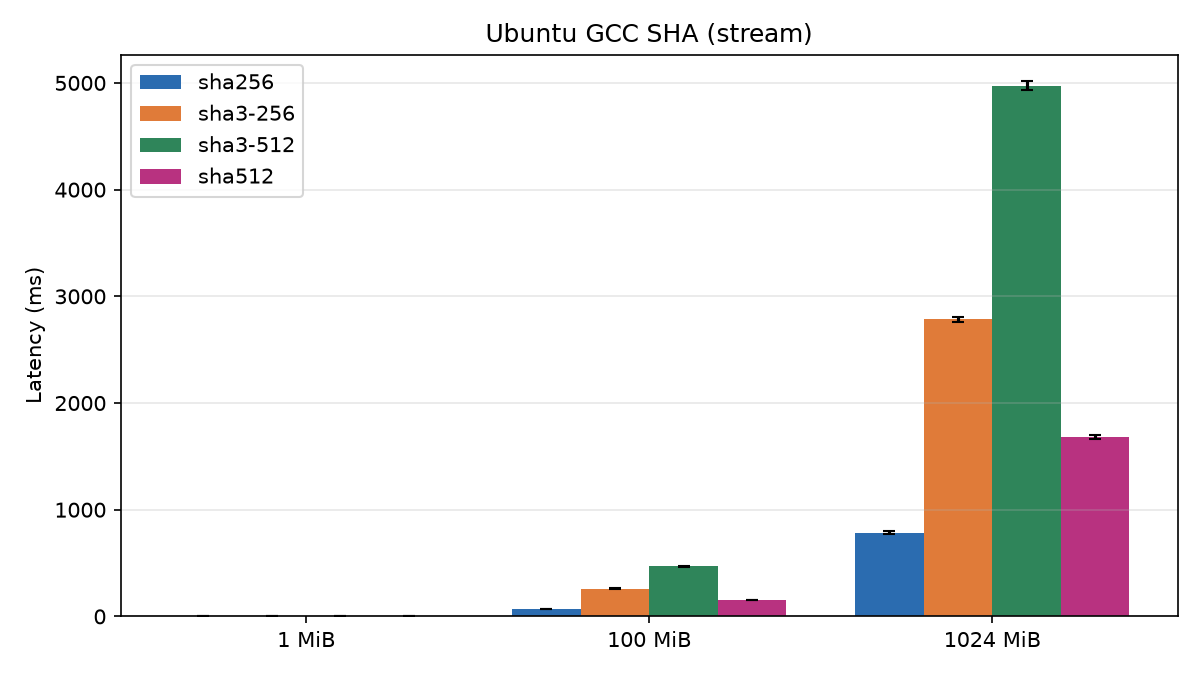

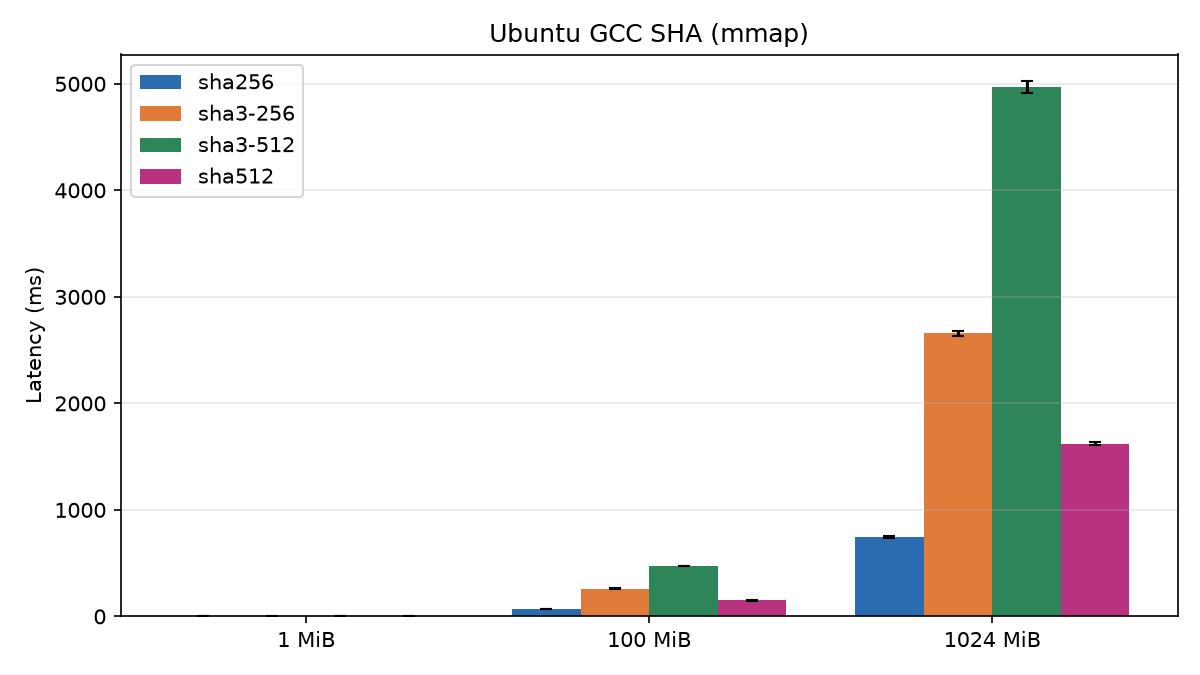

In [4]:
with tempfile.TemporaryDirectory(prefix="lab4-nb-") as tmp:
    for metric, ci, ylabel, prefix in (
        ("mbps_mean", "mbps_ci95", "Throughput (MB/s)", "throughput"),
        ("elapsed_mean_ms", "elapsed_ci95_ms", "Latency (ms)", "latency"),
    ):
        for io in ("stream", "mmap"):
            out = Path(tmp) / f"{prefix}_{io}.png"
            plot_metric(rows, io, metric, ci, ylabel, "Ubuntu GCC SHA", out)
            display(Image(filename=str(out)))


## What the data shows

- SHA-256 is fastest at every size (about 1.4 GB/s at 1 GiB); SHA3-512 is
  slowest (about 0.22 GB/s).
- `mmap` gains 4–8% for SHA-256/SHA-512 at 100 MiB and 1 GiB. SHA-3 is flat
  because the Keccak permutation dominates, so removing one copy changes little.
- CPU is about 100% of one core in every row: no parallelism inside a hash.
- These are warm tmpfs numbers with no CPU pinning; treat absolute MB/s as
  indicative, not as a hardware peak.
